
# Shin–Metiu full-potential sparse Fourier workflow

This notebook keeps the **nonharmonic/full-potential** formulation and changes only the Fourier-fit workflow.

The pipeline is:

1. Build a large real half-lattice Fourier dictionary and sweep the Fourier box and order-weighted ridge parameters.
2. Reject raw fits whose full-potential RMSD exceeds `RAW_V_RMSE_MAX`.
3. From every surviving raw fit, select the top `N` modes using either
   \[
   C_\mu=\sqrt{A_\mu^2+B_\mu^2}
   \]
   or the force-scale score
   \[
   |\mu|C_\mu.
   \]
4. Refit \(C_0,A_\mu,B_\mu\) on the reduced support, using the same weighted-ridge form.
5. Calculate PES, force, TGIFS, and coefficient metrics for every reduced fit.
6. Run the classical CPU dynamics only for the reduced candidates.

The physical Hamiltonian, initial state, Fock basis, kinetic operator, quadrature projection, and CPU propagation are unchanged from the uploaded notebook.


In [2]:
import math
from pathlib import Path
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from numpy.polynomial.hermite import hermgauss
from scipy.linalg import eigh
from scipy.special import erf, eval_hermite, factorial


## Physical and numerical parameters

These match the previous nonharmonic Shin–Metiu notebook. `omega` and `Omega` define only the coordinate/Fock scaling; there is **no harmonic potential term** in the Hamiltonian used below.


In [3]:

# Atomic units
hbar = 1.0
me = 1.0
M = 1836.0

# Shin-Metiu potential
L_SM = 19.0
Z_nuc = 1.0
Rl = 3.1
Rr = 4.0
Rf = 5.0

# Coordinate/Fock-basis scales only
r0 = 0.0
R0 = 0.0
omega = 0.025
Omega = 0.0025

l_r = np.sqrt(hbar / (me * omega))
l_R = np.sqrt(hbar / (M * Omega))

# CPU Fock truncation
Nr = 16
NR = 128
Nquad_r = 200
Nquad_R = 200

# Physical-coordinate grid used to fit full V_SM
r_surface = np.arange(-30.0, 30.0, 1.0)
R_surface = np.arange(-6.0, 6.0, 1.0)

# Dynamics output grid
times = np.linspace(0.0, 1400.0, 251)
AU_TIME_TO_FS = 0.024188843265857

# ------------------------------------------------------------------
# 1. Raw Fourier sweep
# Convention: first entry is R, second is r.
#
# The code permits several Fourier-order limits for generality.
# To keep the large half-lattice fixed, leave one entry here.
# ------------------------------------------------------------------
FOURIER_BASIS = 'half_lattice'

FOURIER_ORDERS = [
    (14, 14),
]

FOURIER_BOXES = [(20,80),(30,80),(40,80)]
#[(30,80),(40,80),(50,80)]#[(x, y) for x in np.arange(10, 100, 10) for y in np.arange(10, 100, 10)]
#[(40,70),
#(80,60),
#(70,60),
#]
#[(x, y) for x in np.arange(10, 100, 10) for y in np.arange(10, 100, 10)]
      #(30,75)            [(30,80),(40,80),(40,60)]
#[
#    (40.0, 60.0),
#    (60.0, 80.0),
#    (80.0, 100.0),
#]

RIDGE_LAMBDAS = [
    1e-4,
]

ORDER_WEIGHT_STRENGTHS = [
    10.0,
]

ORDER_WEIGHT_POWERS = [
    1.0,
]

# ------------------------------------------------------------------
# 2. Raw-fit screening
# ------------------------------------------------------------------
RAW_V_RMSE_MAX = 1.0e-2

# ------------------------------------------------------------------
# 3. Sparse mode selection
# ------------------------------------------------------------------
TOP_N_VALUES = [
    50,
]

# 'amplitude'   -> C_mu = sqrt(A_mu^2 + B_mu^2)
# 'force_scale' -> |mu| C_mu, where |mu| is the physical wavevector norm
SELECTION_METHODS = [
    #'amplitude',
    'force_scale',
]

# ------------------------------------------------------------------
# 4. Reduced-support refit
# ------------------------------------------------------------------
REFIT_RIDGE_MULTIPLIER = 1.0

# ------------------------------------------------------------------
# 5. TGIFS diagnostics
# Set this to the actual TGIFS potential substep for circuit estimates.
# ------------------------------------------------------------------
TGIFS_DT_FOR_DIAGNOSTICS = times[1] - times[0]
COEFF_TOL = 1e-12

RESULTS_DIR = Path('fullV_sparse_fourier_workflow')
RESULTS_DIR.mkdir(exist_ok=True)

SKIP_EXISTING_DYNAMICS = True
PLOT_REDUCED_COEFFICIENTS = True

RAW_SWEEP_CONFIGS = list(product(
    FOURIER_ORDERS,
    FOURIER_BOXES,
    RIDGE_LAMBDAS,
    ORDER_WEIGHT_STRENGTHS,
    ORDER_WEIGHT_POWERS,
))

print('l_r =', l_r)
print('l_R =', l_R)
print('CPU Fock shape (r,R) =', (Nr, NR))
print('raw sweep points =', len(RAW_SWEEP_CONFIGS))


l_r = 6.324555320336759
l_R = 0.46676002800933664
CPU Fock shape (r,R) = (16, 128)
raw sweep points = 3



## Why the regularization is useful

For a fixed Fourier dictionary the unregularized fit solves

$$
\min_c \|Dc-y\|_2^2,
$$

where $c=(C_0,A_1,\ldots,A_M,B_1,\ldots,B_M)$.

On the finite Shin–Metiu fitting rectangle, many high-order Fourier columns can be nearly linearly dependent. Ordinary least squares can therefore use large positive and negative coefficients that cancel in the reconstructed PES. That can be harmless for classical PES evaluation but is undesirable for TGIFS because each sine/cosine term is synthesized separately.

The order-weighted ridge fit solves

$$
\min_c
\left[
\|Dc-y\|_2^2
+
\lambda \sum_\mu
w_\mu(A_\mu^2+B_\mu^2)
\right],
$$

with $C_0$ left unpenalized. The mode weight is

$$
w_\mu =
1+\eta
\left[
\left(\frac{m_R}{N_R-1}\right)^2+
\left(\frac{m_r}{N_r-1}\right)^2
\right]^p.
$$

`RIDGE_LAMBDAS` changes the overall pressure toward smaller coefficients. `ORDER_WEIGHT_STRENGTHS` adds extra cost to high-order modes, and `ORDER_WEIGHT_POWERS` controls how sharply that cost grows near the cutoff.

The fit is solved by augmented least squares rather than normal equations:

$$
\begin{bmatrix}D\\ \sqrt{\lambda W}\end{bmatrix}c
\approx
\begin{bmatrix}y\\0\end{bmatrix}.
$$

This avoids explicitly forming \(D^\mathsf{T}D\), which would square the condition number.

Regularization is only the first compression stage. After screening raw fits by PES RMSD, the workflow explicitly selects a fixed circuit budget (`TOP_N_VALUES`) and **refits on that reduced support**.


## Shin–Metiu potential

In [4]:
def erf_coulomb(x, sigma):
    x = np.asarray(x)
    ax = np.abs(x)
    out = np.empty_like(ax, dtype=float)
    mask = ax > 1e-12
    out[mask] = erf(ax[mask] / sigma) / ax[mask]
    out[~mask] = 2.0 / (np.sqrt(np.pi) * sigma)
    return out


def V_SM(r, R):
    V_nn = (
        Z_nuc**2 / np.abs(R - L_SM / 2.0)
        + Z_nuc**2 / np.abs(R + L_SM / 2.0)
    )

    V_e_mobile = -Z_nuc * erf_coulomb(r - R, Rf)
    V_e_right = -Z_nuc * erf_coulomb(r - L_SM / 2.0, Rr)
    V_e_left = -Z_nuc * erf_coulomb(r + L_SM / 2.0, Rl)

    return V_nn + V_e_mobile + V_e_right + V_e_left



## Half-lattice Fourier basis, weighted-ridge fitting, support selection, and metrics

The half-lattice keeps one representative from every global \(\boldsymbol\mu\leftrightarrow-\boldsymbol\mu\) pair while retaining both mixed-sign directions such as \((m_R,m_r)\) and \((m_R,-m_r)\).

Two top-\(N\) ranking choices are implemented:

- `amplitude`: \(C_\mu=\sqrt{A_\mu^2+B_\mu^2}\);
- `force_scale`: \(|\mu|C_\mu\), a simple estimate of the maximum gradient scale of that Fourier mode.


In [5]:

def normalize_order(order):
    if np.isscalar(order):
        return int(order), int(order)
    return int(order[0]), int(order[1])


def build_mvec(NF, basis=FOURIER_BASIS):
    NF_R, NF_r = normalize_order(NF)

    if basis == 'half_lattice':
        modes = []

        for mr in range(1, NF_r):
            modes.append([0, mr])

        for mR in range(1, NF_R):
            for mr in range(-(NF_r - 1), NF_r):
                modes.append([mR, mr])

        return np.asarray(modes, dtype=int)

    if basis == 'positive_only':
        return np.asarray([
            [mR, mr]
            for mR in range(NF_R)
            for mr in range(NF_r)
            if mR > 0 or mr > 0
        ], dtype=int)

    raise ValueError(f'unknown Fourier basis: {basis}')


def order_weights(mvec, NF, strength, power):
    NF_R, NF_r = normalize_order(NF)

    scale_R = max(NF_R - 1, 1)
    scale_r = max(NF_r - 1, 1)

    order2 = (
        (mvec[:, 0] / scale_R)**2
        + (mvec[:, 1] / scale_r)**2
    )

    order_norm = np.sqrt(order2)
    weights = 1.0 + strength * order2**power

    return weights, order_norm


r_mesh_fit, R_mesh_fit = np.meshgrid(
    r_surface,
    R_surface,
    indexing='xy',
)

V_target_surface = V_SM(r_mesh_fit, R_mesh_fit)
V_target_flat = V_target_surface.ravel()


def erf_coulomb_prime(x, sigma):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)

    mask = np.abs(x) > 1e-10
    xm = x[mask]

    out[mask] = (
        (2.0 / (np.sqrt(np.pi) * sigma))
        * np.exp(-(xm / sigma)**2)
        * xm
        - erf(xm / sigma)
    ) / xm**2

    return out


def forces_SM(r, R):
    r = np.asarray(r, dtype=float)
    R = np.asarray(R, dtype=float)

    a = L_SM / 2.0

    gp_mobile = erf_coulomb_prime(r - R, Rf)
    gp_right = erf_coulomb_prime(r - a, Rr)
    gp_left = erf_coulomb_prime(r + a, Rl)

    force_r = Z_nuc * (
        gp_mobile
        + gp_right
        + gp_left
    )

    force_R = (
        Z_nuc**2 * (R - a) / np.abs(R - a)**3
        + Z_nuc**2 * (R + a) / np.abs(R + a)**3
        - Z_nuc * gp_mobile
    )

    return force_r, force_R


force_r_target_surface, force_R_target_surface = forces_SM(
    r_mesh_fit,
    R_mesh_fit,
)

force_r_target_flat = force_r_target_surface.ravel()
force_R_target_flat = force_R_target_surface.ravel()


def build_design(mu_phys):
    phase = (
        R_mesh_fit.ravel()[:, None] * mu_phys[None, :, 0]
        + r_mesh_fit.ravel()[:, None] * mu_phys[None, :, 1]
    )

    design = np.concatenate([
        np.ones((V_target_flat.size, 1)),
        np.cos(phase),
        np.sin(phase),
    ], axis=1)

    return design, phase


def solve_weighted_ridge(
    mvec,
    mu_phys,
    NF,
    ridge_lambda,
    order_strength,
    order_power,
):
    design, phase = build_design(mu_phys)

    mode_weight, order_norm = order_weights(
        mvec,
        NF,
        strength=order_strength,
        power=order_power,
    )

    penalty = np.concatenate([
        [0.0],
        mode_weight,
        mode_weight,
    ])

    reg_matrix = np.diag(
        np.sqrt(ridge_lambda * penalty)
    )

    design_aug = np.vstack([
        design,
        reg_matrix,
    ])

    target_aug = np.concatenate([
        V_target_flat,
        np.zeros(design.shape[1]),
    ])

    pars, *_ = np.linalg.lstsq(
        design_aug,
        target_aug,
        rcond=None,
    )

    nmode = len(mvec)

    return {
        'C0': float(pars[0]),
        'A': pars[1:1 + nmode],
        'B': pars[1 + nmode:],
        'phase_fit_grid': phase,
        'design_condition': float(np.linalg.cond(design)),
        'regularized_condition': float(np.linalg.cond(design_aug)),
        'mode_weight': mode_weight,
        'order_norm': order_norm,
    }


def calculate_fit_metrics(fit):
    A = fit['A']
    B = fit['B']
    mu_phys = fit['mu_phys']

    phase = fit.get('phase_fit_grid')
    if phase is None:
        _, phase = build_design(mu_phys)

    sin_phase = np.sin(phase)
    cos_phase = np.cos(phase)

    V_pred = (
        fit['C0']
        + cos_phase @ A
        + sin_phase @ B
    )

    V_residual = V_pred - V_target_flat

    force_factor = (
        sin_phase * A[None, :]
        - cos_phase * B[None, :]
    )

    force_R_pred = force_factor @ mu_phys[:, 0]
    force_r_pred = force_factor @ mu_phys[:, 1]

    force_R_residual = force_R_pred - force_R_target_flat
    force_r_residual = force_r_pred - force_r_target_flat

    amplitude = np.sqrt(A**2 + B**2)
    mu_norm = np.linalg.norm(mu_phys, axis=1)
    force_scale = mu_norm * amplitude

    amp2 = amplitude**2
    if np.sum(amp2) > 0.0:
        mode_probability = amp2 / np.sum(amp2)
    else:
        mode_probability = np.zeros_like(amplitude)

    mu_dimless = mu_phys * np.array([l_R, l_r])[None, :]
    kappa = 0.5 * mu_dimless
    kappa_norm = np.linalg.norm(kappa, axis=1)

    theta_A = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(A)
    theta_B = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(B)

    nonzero_A = np.abs(A) > COEFF_TOL
    nonzero_B = np.abs(B) > COEFF_TOL

    metrics = {
        'v_rmse': float(np.sqrt(np.mean(V_residual**2))),
        'v_max_abs_error': float(np.max(np.abs(V_residual))),

        'force_r_rmse': float(np.sqrt(np.mean(force_r_residual**2))),
        'force_R_rmse': float(np.sqrt(np.mean(force_R_residual**2))),
        'force_combined_rmse': float(np.sqrt(
            0.5 * (
                np.mean(force_r_residual**2)
                + np.mean(force_R_residual**2)
            )
        )),
        'force_r_max_abs_error': float(np.max(np.abs(force_r_residual))),
        'force_R_max_abs_error': float(np.max(np.abs(force_R_residual))),

        'n_modes': int(len(A)),
        'max_abs_A': float(np.max(np.abs(A))) if len(A) else 0.0,
        'max_abs_B': float(np.max(np.abs(B))) if len(B) else 0.0,
        'sum_abs_A': float(np.sum(np.abs(A))),
        'sum_abs_B': float(np.sum(np.abs(B))),
        'max_amp': float(np.max(amplitude)) if len(amplitude) else 0.0,
        'sum_amp': float(np.sum(amplitude)),
        'l2_amp': float(np.sqrt(np.sum(amplitude**2))),
        'max_force_scale': float(np.max(force_scale)) if len(force_scale) else 0.0,
        'sum_force_scale': float(np.sum(force_scale)),
        'effective_modes': float(1.0 / np.sum(mode_probability**2))
            if np.sum(mode_probability**2) > 0 else 0.0,

        'theta_max': float(max(
            np.max(theta_A) if len(theta_A) else 0.0,
            np.max(theta_B) if len(theta_B) else 0.0,
        )),
        'theta_sum': float(np.sum(theta_A) + np.sum(theta_B)),
        'max_kappa': float(np.max(kappa_norm)) if len(kappa_norm) else 0.0,
        'n_tgifs_gates': int(np.count_nonzero(nonzero_A) + np.count_nonzero(nonzero_B)),
    }

    fit.update({
        'amplitude': amplitude,
        'mu_norm': mu_norm,
        'force_scale': force_scale,
        'mode_probability': mode_probability,
        'mu_dimless': mu_dimless,
        'kappa': kappa,
        'kappa_norm': kappa_norm,
        'V_fit_surface': V_pred.reshape(V_target_surface.shape),
        'force_r_fit_surface': force_r_pred.reshape(V_target_surface.shape),
        'force_R_fit_surface': force_R_pred.reshape(V_target_surface.shape),
        'metrics': metrics,
    })

    return fit


def fit_fourier_full_V_ridge(
    fourier_box,
    NF,
    ridge_lambda,
    order_strength,
    order_power,
    basis=FOURIER_BASIS,
):
    fourier_box = np.asarray(fourier_box, dtype=float)
    NF = normalize_order(NF)

    mvec = build_mvec(NF, basis=basis)
    mu_phys = (
        mvec
        * (2.0 * np.pi / fourier_box)[None, :]
    )

    solved = solve_weighted_ridge(
        mvec=mvec,
        mu_phys=mu_phys,
        NF=NF,
        ridge_lambda=ridge_lambda,
        order_strength=order_strength,
        order_power=order_power,
    )

    fit = {
        'basis': basis,
        'fourier_box': fourier_box,
        'NF': np.asarray(NF, dtype=int),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'ridge_lambda': float(ridge_lambda),
        'order_strength': float(order_strength),
        'order_power': float(order_power),
        'selection_method': 'raw',
        'top_n_requested': int(len(mvec)),
        'parent_id': '',
        **solved,
    }

    return calculate_fit_metrics(fit)


def mode_selection_scores(fit, method):
    if method == 'amplitude':
        return fit['amplitude']

    if method == 'force_scale':
        return fit['force_scale']

    raise ValueError(
        "selection method must be 'amplitude' or 'force_scale'"
    )


def select_top_mode_indices(fit, top_n, method):
    scores = mode_selection_scores(fit, method)

    top_n = min(int(top_n), len(scores))
    if top_n <= 0:
        raise ValueError('top_n must be positive')

    idx = np.argsort(scores)[-top_n:]
    idx = idx[np.argsort(scores[idx])[::-1]]

    return idx


def refit_reduced_support(
    raw_fit,
    selected_idx,
    selection_method,
    top_n_requested,
):
    mvec = raw_fit['mvec'][selected_idx].copy()
    mu_phys = raw_fit['mu_phys'][selected_idx].copy()

    ridge_lambda = (
        REFIT_RIDGE_MULTIPLIER
        * raw_fit['ridge_lambda']
    )

    solved = solve_weighted_ridge(
        mvec=mvec,
        mu_phys=mu_phys,
        NF=raw_fit['NF'],
        ridge_lambda=ridge_lambda,
        order_strength=raw_fit['order_strength'],
        order_power=raw_fit['order_power'],
    )

    fit = {
        'basis': raw_fit['basis'],
        'fourier_box': raw_fit['fourier_box'].copy(),
        'NF': raw_fit['NF'].copy(),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'ridge_lambda': float(ridge_lambda),
        'parent_ridge_lambda': float(raw_fit['ridge_lambda']),
        'order_strength': float(raw_fit['order_strength']),
        'order_power': float(raw_fit['order_power']),
        'selection_method': selection_method,
        'top_n_requested': int(top_n_requested),
        'parent_id': raw_fit['fit_id'],
        **solved,
    }

    return calculate_fit_metrics(fit)


def evaluate_fourier_full_V(r, R, fit):
    rvals = np.asarray(r).ravel()
    Rvals = np.asarray(R).ravel()

    r_eval, R_eval = np.meshgrid(
        rvals,
        Rvals,
        indexing='ij',
    )

    phase = (
        R_eval.ravel()[:, None] * fit['mu_phys'][None, :, 0]
        + r_eval.ravel()[:, None] * fit['mu_phys'][None, :, 1]
    )

    values = (
        fit['C0']
        + np.cos(phase) @ fit['A']
        + np.sin(phase) @ fit['B']
    )

    return values.reshape(
        rvals.size,
        Rvals.size,
    )


def raw_fit_id(NF, fourier_box, ridge_lambda, order_strength, order_power):
    NF_R, NF_r = normalize_order(NF)
    box_R, box_r = np.asarray(fourier_box, dtype=float)

    return (
        f'boxR{box_R:g}_boxr{box_r:g}'
        f'_NFR{NF_R}_NFr{NF_r}'
        f'_lam{ridge_lambda:g}'
        f'_ow{order_strength:g}'
        f'_op{order_power:g}'
    )


def reduced_fit_id(fit):
    return (
        fit['parent_id']
        + f"_sel-{fit['selection_method']}"
        + f"_top{fit['top_n_requested']}"
    )


def fit_summary_row(fit):
    row = {
        'fit_id': fit.get('fit_id', reduced_fit_id(fit)),
        'parent_id': fit.get('parent_id', ''),
        'basis': fit['basis'],
        'box_R': float(fit['fourier_box'][0]),
        'box_r': float(fit['fourier_box'][1]),
        'NF_R': int(fit['NF'][0]),
        'NF_r': int(fit['NF'][1]),
        'ridge_lambda': float(fit['ridge_lambda']),
        'order_strength': float(fit['order_strength']),
        'order_power': float(fit['order_power']),
        'selection_method': fit['selection_method'],
        'top_n_requested': int(fit['top_n_requested']),
        'design_condition': float(fit['design_condition']),
        'regularized_condition': float(fit['regularized_condition']),
    }

    row.update(fit['metrics'])
    return row


## Initial state in the same Fock basis

In [6]:
# Sinc-DVR is used only to obtain the second BO electronic state at R=-4.
n_dvr = 150
dx = 18.5 / n_dvr
r_dvr = np.array([i * dx for i in range(-n_dvr, n_dvr + 1)])

d2xmat = np.array([
    [
        -np.pi**2 / (3.0 * dx**2)
        if i == j
        else -2.0 * (-1)**(i - j) / (dx * (i - j))**2
        for j in range(-n_dvr, n_dvr + 1)
    ]
    for i in range(-n_dvr, n_dvr + 1)
])


def electronic_hamiltonian(R_value):
    return -0.5 * d2xmat + np.diag(V_SM(r_dvr, R_value))


_, eigvec_e = eigh(electronic_hamiltonian(-4.0))
psi0_e = eigvec_e[:, 1]


def ho_basis_realspace(N, q, q0, l):
    x = (q - q0) / l
    phi = np.zeros((N, len(q)))
    for n in range(N):
        norm = np.pi**(-0.25) / (np.sqrt(l) * np.sqrt(2.0**n * factorial(n)))
        phi[n] = norm * eval_hermite(n, x) * np.exp(-x**2 / 2.0)
    return phi


def initial_fock_coefficients(Nr_basis=Nr, NR_basis=NR):
    psi_e = psi0_e.astype(complex).copy()
    psi_e /= np.sqrt(np.trapezoid(np.abs(psi_e)**2, r_dvr))

    phi_r = ho_basis_realspace(Nr_basis, r_dvr, r0, l_r)
    c_e = np.array([
        np.trapezoid(np.conj(phi_r[n]) * psi_e, r_dvr)
        for n in range(Nr_basis)
    ], dtype=complex)

    R_grid = np.linspace(-15.0, 15.0, 4000)
    psi_R = np.exp(-2.85 * (R_grid + 4.0)**2)
    psi_R /= np.sqrt(np.trapezoid(np.abs(psi_R)**2, R_grid))

    phi_R = ho_basis_realspace(NR_basis, R_grid, R0, l_R)
    c_R = np.array([
        np.trapezoid(np.conj(phi_R[n]) * psi_R, R_grid)
        for n in range(NR_basis)
    ], dtype=complex)

    captured_e = np.sum(np.abs(c_e)**2)
    captured_R = np.sum(np.abs(c_R)**2)

    c_e /= np.linalg.norm(c_e)
    c_R /= np.linalg.norm(c_R)

    return c_e, c_R, captured_e, captured_R


c_e_cpu, c_R_cpu, cap_e, cap_R = initial_fock_coefficients()
psi0_cpu = np.outer(c_e_cpu, c_R_cpu).ravel()

print('captured initial norm before normalization:')
print('  electron =', cap_e)
print('  nucleus  =', cap_R)


captured initial norm before normalization:
  electron = 0.9974529177722165
  nucleus  = 1.0000000000000104


## CPU kinetic operator, potential projection, propagation, and observables

In [193]:
def X_fock(N):
    X = np.zeros((N, N), dtype=complex)
    for n in range(N - 1):
        val = np.sqrt(n + 1.0) / np.sqrt(2.0)
        X[n, n + 1] = val
        X[n + 1, n] = val
    return X


def P_fock(N):
    P = np.zeros((N, N), dtype=complex)
    for n in range(N - 1):
        val = np.sqrt(n + 1.0) / np.sqrt(2.0)
        P[n, n + 1] = -1j * val
        P[n + 1, n] = +1j * val
    return P


def kinetic_1d(N, mass, l):
    P = P_fock(N)
    return (hbar**2 / (2.0 * mass * l**2)) * (P @ P)


T_r_cpu = kinetic_1d(Nr, me, l_r)
T_R_cpu = kinetic_1d(NR, M, l_R)
T_cpu = (
    np.kron(T_r_cpu, np.eye(NR))
    + np.kron(np.eye(Nr), T_R_cpu)
)


def ho_polynomials(N, x):
    B = np.zeros((N, len(x)))
    for n in range(N):
        B[n] = np.pi**(-0.25) * eval_hermite(n, x) / np.sqrt(2.0**n * factorial(n))
    return B


xr, wr = hermgauss(Nquad_r)
xR, wR = hermgauss(Nquad_R)
r_quad = r0 + l_r * xr
R_quad = R0 + l_R * xR
Br_quad = ho_polynomials(Nr, xr) * np.sqrt(wr)[None, :]
BR_quad = ho_polynomials(NR, xR) * np.sqrt(wR)[None, :]


def potential_matrix(potential_function):
    V = potential_function(r_quad[:, None], R_quad[None, :])
    if V.shape != (Nquad_r, Nquad_R):
        raise ValueError(f'potential returned {V.shape}; expected {(Nquad_r, Nquad_R)}')

    out = np.einsum(
        'ni,mi,aj,bj,ij->namb',
        Br_quad, Br_quad, BR_quad, BR_quad, V,
        optimize=True,
    )
    return out.reshape(Nr * NR, Nr * NR)


def evolve_cpu_fullV(Vmat, psi0, times):
    H = T_cpu + Vmat
    H = 0.5 * (H + H.conj().T)
    E, U = eigh(H)
    c0 = U.conj().T @ psi0
    phases = np.exp(-1j * np.outer(times, E) / hbar)
    return (phases * c0) @ U.T


Xr_cpu = X_fock(Nr)
XR_cpu = X_fock(NR)

r_operator_cpu = r0 * np.eye(Nr) + l_r * Xr_cpu
R_operator_cpu = R0 * np.eye(NR) + l_R * XR_cpu
r2_operator_cpu = r_operator_cpu @ r_operator_cpu
R2_operator_cpu = R_operator_cpu @ R_operator_cpu


def cpu_moments(psi_t):
    C = np.asarray(psi_t).reshape(len(psi_t), Nr, NR)

    mean_r = np.einsum('tna,nm,tma->t', C.conj(), r_operator_cpu, C, optimize=True).real
    mean_r2 = np.einsum('tna,nm,tma->t', C.conj(), r2_operator_cpu, C, optimize=True).real

    mean_R = np.einsum('tna,ab,tnb->t', C.conj(), R_operator_cpu, C, optimize=True).real
    mean_R2 = np.einsum('tna,ab,tnb->t', C.conj(), R2_operator_cpu, C, optimize=True).real

    sigma_r = np.sqrt(np.maximum(mean_r2 - mean_r**2, 0.0))
    sigma_R = np.sqrt(np.maximum(mean_R2 - mean_R**2, 0.0))

    return mean_r, sigma_r, mean_R, sigma_R



## Stage 1 — Sweep the large half-lattice, Fourier box, and regularization

This stage generates the raw fits and diagnostics but does **not** run CPU dynamics.


In [194]:
raw_fits = []
raw_rows = []

for NF, fourier_box, ridge_lambda, order_strength, order_power in RAW_SWEEP_CONFIGS:
    fit_id = raw_fit_id(
        NF,
        fourier_box,
        ridge_lambda,
        order_strength,
        order_power,
    )

    print('raw:', fit_id)

    fit = fit_fourier_full_V_ridge(
        fourier_box=fourier_box,
        NF=NF,
        ridge_lambda=ridge_lambda,
        order_strength=order_strength,
        order_power=order_power,
        basis=FOURIER_BASIS,
    )

    fit['fit_id'] = fit_id

    raw_fits.append(fit)
    raw_rows.append(fit_summary_row(fit))

raw_summary_df = pd.DataFrame(raw_rows)
raw_summary_df = raw_summary_df.sort_values('v_rmse').reset_index(drop=True)

raw_summary_csv = RESULTS_DIR / 'raw_fit_summary.csv'
raw_summary_df.to_csv(raw_summary_csv, index=False)

print()
print('saved:', raw_summary_csv)
raw_summary_df


raw: boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1
raw: boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1
raw: boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1

saved: fullV_sparse_fourier_workflow/raw_fit_summary.csv


,fit_id,parent_id,basis,box_R,box_r,NF_R,NF_r,ridge_lambda,order_strength,order_power,...,max_amp,sum_amp,l2_amp,max_force_scale,sum_force_scale,effective_modes,theta_max,theta_sum,max_kappa,n_tgifs_gates
0,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,40.0,80.0,14,14,0.0001,10.0,1.0,...,0.064423,1.336585,0.157757,0.012917,0.821030,15.942064,0.179980,4.644692,3.263723,728
1,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,30.0,80.0,14,14,0.0001,10.0,1.0,...,0.078873,1.291740,0.165717,0.013650,0.906586,11.213849,0.220397,4.502928,3.290674,728
2,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,20.0,80.0,14,14,0.0001,10.0,1.0,...,0.114525,1.311328,0.191321,0.020320,1.124755,6.409911,0.320378,4.599635,3.366489,727



## Stage 2 — Discard poor raw fits using the PES RMSD

Only raw fits with `v_rmse <= RAW_V_RMSE_MAX` proceed.


In [195]:

surviving_raw_fits = [
    fit
    for fit in raw_fits
    if fit['metrics']['v_rmse'] <= RAW_V_RMSE_MAX
]

discarded_raw_fits = [
    fit
    for fit in raw_fits
    if fit['metrics']['v_rmse'] > RAW_V_RMSE_MAX
]

print('raw fits total     =', len(raw_fits))
print('raw fits retained  =', len(surviving_raw_fits))
print('raw fits discarded =', len(discarded_raw_fits))
print('RMSD threshold     =', RAW_V_RMSE_MAX)

if len(surviving_raw_fits) == 0:
    raise RuntimeError(
        'No raw fit passed RAW_V_RMSE_MAX. '
        'Increase the threshold or change the sweep.'
    )

screened_raw_df = pd.DataFrame([
    fit_summary_row(fit)
    for fit in surviving_raw_fits
]).sort_values('v_rmse').reset_index(drop=True)

screened_raw_df


raw fits total     = 3
raw fits retained  = 3
raw fits discarded = 0
RMSD threshold     = 0.01


,fit_id,parent_id,basis,box_R,box_r,NF_R,NF_r,ridge_lambda,order_strength,order_power,...,max_amp,sum_amp,l2_amp,max_force_scale,sum_force_scale,effective_modes,theta_max,theta_sum,max_kappa,n_tgifs_gates
0,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,40.0,80.0,14,14,0.0001,10.0,1.0,...,0.064423,1.336585,0.157757,0.012917,0.821030,15.942064,0.179980,4.644692,3.263723,728
1,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,30.0,80.0,14,14,0.0001,10.0,1.0,...,0.078873,1.291740,0.165717,0.013650,0.906586,11.213849,0.220397,4.502928,3.290674,728
2,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,,half_lattice,20.0,80.0,14,14,0.0001,10.0,1.0,...,0.114525,1.311328,0.191321,0.020320,1.124755,6.409911,0.320378,4.599635,3.366489,727


## Stages 3–5 — Top-\(N\) selection, reduced-support refit, and metrics

For every surviving raw fit:

1. rank modes by \(C_\mu\) or \(|\mu|C_\mu\);
2. keep the requested top \(N\);
3. refit only those modes;
4. recompute PES, force, coefficient, and TGIFS metrics.


In [196]:

reduced_fits = []
reduced_rows = []

for raw_fit in surviving_raw_fits:
    for method in SELECTION_METHODS:
        for top_n in TOP_N_VALUES:

            selected_idx = select_top_mode_indices(
                raw_fit,
                top_n=top_n,
                method=method,
            )

            reduced_fit = refit_reduced_support(
                raw_fit=raw_fit,
                selected_idx=selected_idx,
                selection_method=method,
                top_n_requested=top_n,
            )

            reduced_fit['fit_id'] = reduced_fit_id(reduced_fit)

            reduced_fits.append(reduced_fit)
            reduced_rows.append(
                fit_summary_row(reduced_fit)
            )

reduced_summary_df = pd.DataFrame(reduced_rows)

reduced_summary_df = reduced_summary_df.sort_values(
    ['v_rmse', 'n_tgifs_gates', 'theta_max']
).reset_index(drop=True)

reduced_summary_csv = RESULTS_DIR / 'reduced_fit_summary.csv'
reduced_summary_df.to_csv(
    reduced_summary_csv,
    index=False,
)

print('reduced fits =', len(reduced_fits))
print('saved:', reduced_summary_csv)

reduced_summary_df


reduced fits = 3
saved: fullV_sparse_fourier_workflow/reduced_fit_summary.csv


,fit_id,parent_id,basis,box_R,box_r,NF_R,NF_r,ridge_lambda,order_strength,order_power,...,max_amp,sum_amp,l2_amp,max_force_scale,sum_force_scale,effective_modes,theta_max,theta_sum,max_kappa,n_tgifs_gates
0,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,40.0,80.0,14,14,0.0001,10.0,1.0,...,0.209882,1.592598,0.383905,0.046145,0.535741,6.781804,0.586864,5.243528,2.483647,100
1,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,20.0,80.0,14,14,0.0001,10.0,1.0,...,0.364943,1.300083,0.460325,0.052106,0.445413,2.354789,1.021633,4.367565,2.483647,100
2,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,30.0,80.0,14,14,0.0001,10.0,1.0,...,0.273633,1.422149,0.384049,0.043475,0.475310,3.461536,0.765835,4.760830,2.483647,100


In [197]:
reduced_summary_df[['fit_id','box_R','box_r','v_rmse','force_combined_rmse', 'theta_max']].sort_values(by='force_combined_rmse', ascending=True)

,fit_id,box_R,box_r,v_rmse,force_combined_rmse,theta_max
0,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,40.0,80.0,0.001286,0.002458,0.586864
2,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,30.0,80.0,0.001548,0.010762,0.765835
1,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,20.0,80.0,0.001497,0.018140,1.021633



### Metric-space plots

These are useful for selecting candidate representations before CPU propagation.


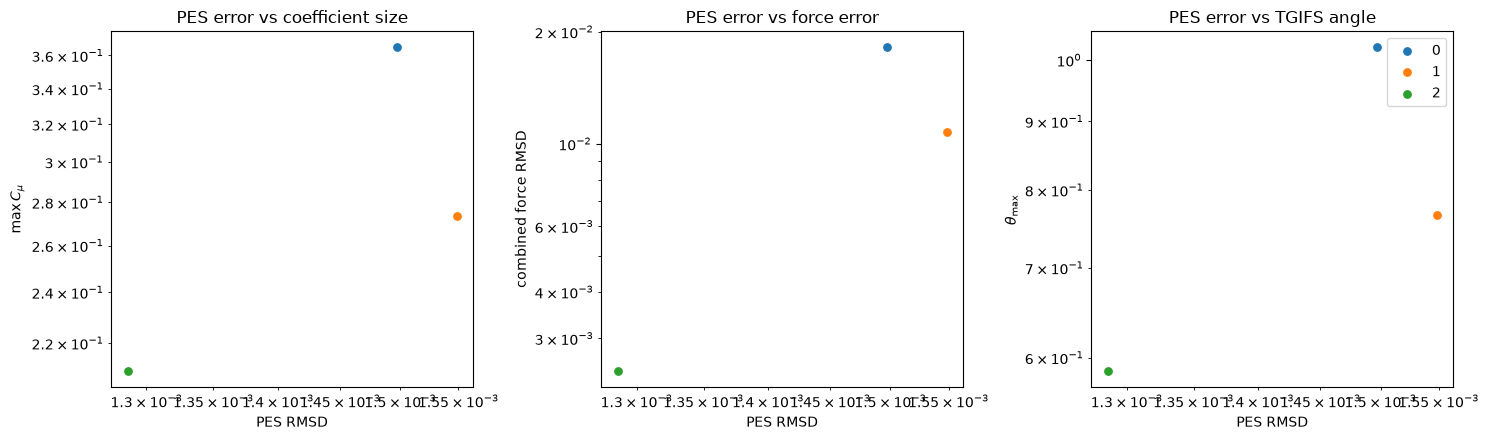

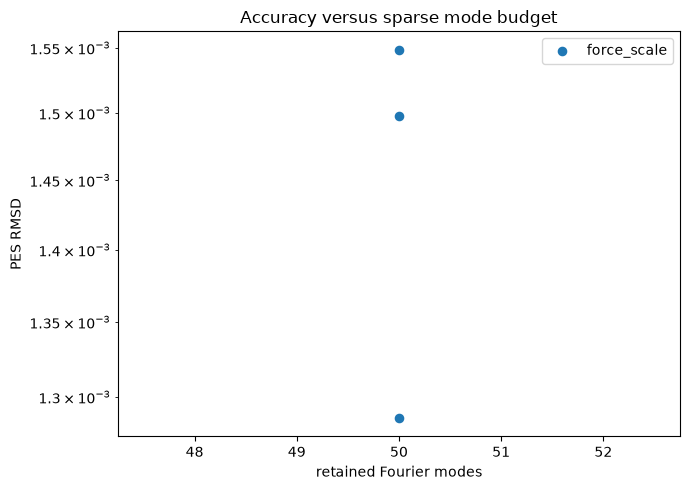

In [198]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, fit in enumerate(reduced_fits):
    m = fit['metrics']

    axes[0].scatter(m['v_rmse'], m['max_amp'], s=28, label=i)
    axes[1].scatter(m['v_rmse'], m['force_combined_rmse'], s=28, label=i)
    axes[2].scatter(m['v_rmse'], m['theta_max'], s=28, label=i)

axes[0].set_xlabel('PES RMSD')
axes[0].set_ylabel(r'$\max C_\mu$')
axes[0].set_title('PES error vs coefficient size')

axes[1].set_xlabel('PES RMSD')
axes[1].set_ylabel('combined force RMSD')
axes[1].set_title('PES error vs force error')

axes[2].set_xlabel('PES RMSD')
axes[2].set_ylabel(r'$\theta_{\max}$')
axes[2].set_title('PES error vs TGIFS angle')

for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')
plt.legend()
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(7, 5))

for method in SELECTION_METHODS:
    rows = reduced_summary_df[
        reduced_summary_df['selection_method'] == method
    ]

    ax.scatter(
        rows['n_modes'],
        rows['v_rmse'],
        label=method,
        s=35,
    )

ax.set_yscale('log')
ax.set_xlabel('retained Fourier modes')
ax.set_ylabel('PES RMSD')
ax.set_title('Accuracy versus sparse mode budget')
ax.legend()
plt.tight_layout()
plt.show()


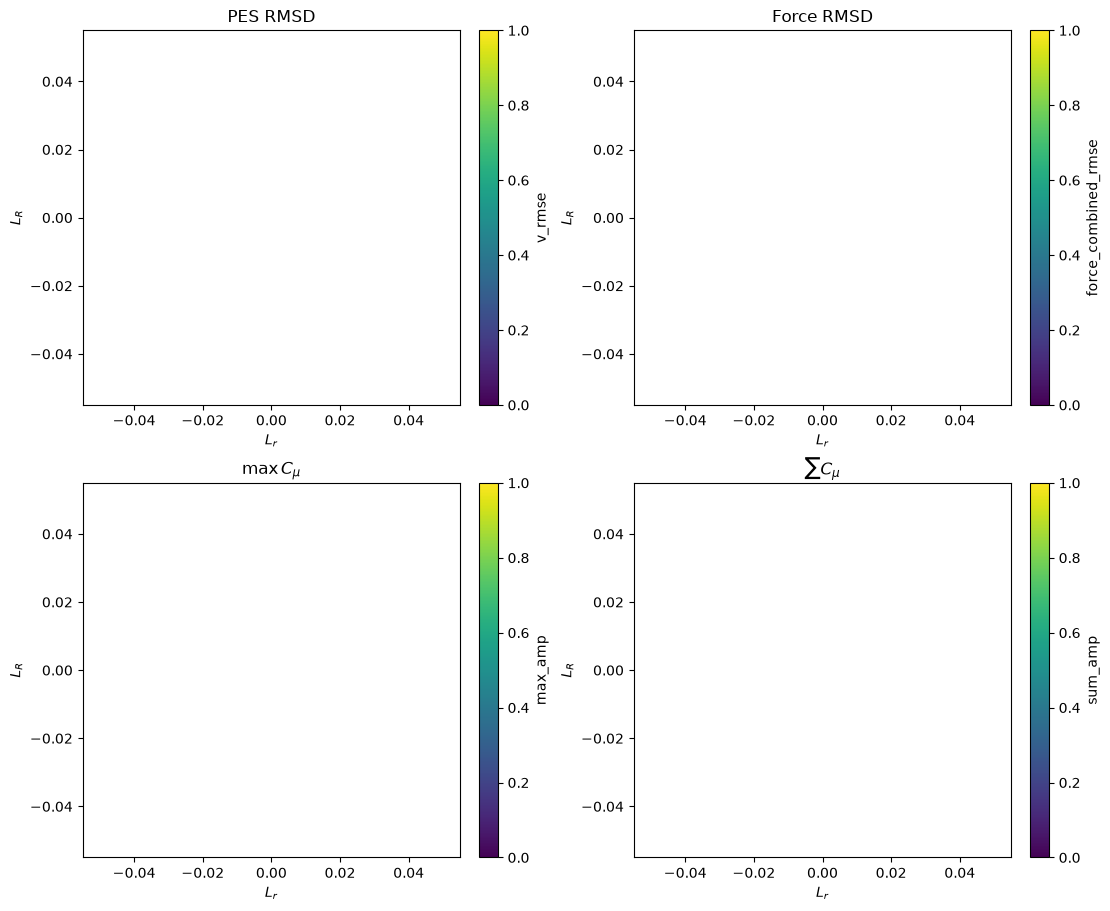

In [199]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Select one family of reduced fits
# ------------------------------------------------------------

df_plot = reduced_summary_df.copy()

df_plot = df_plot[
    (df_plot["selection_method"] == "force_scale")
    & (df_plot["top_n_requested"] == 40)
    & np.isclose(df_plot["ridge_lambda"], 1e-4)
    & np.isclose(df_plot["order_strength"], 10.0)
].copy()


# ------------------------------------------------------------
# Quantities to plot
# ------------------------------------------------------------

metrics = [
    ("v_rmse", "PES RMSD"),
    ("force_combined_rmse", "Force RMSD"),
    ("max_amp", r"$\max C_\mu$"),
    ("sum_amp", r"$\sum C_\mu$"),
]


# ------------------------------------------------------------
# Scatter maps in Fourier-box space
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 9),
    constrained_layout=True
)

axes = axes.ravel()


for ax, (metric, title) in zip(
    axes,
    metrics
):

    sc = ax.scatter(
        df_plot["box_r"],
        df_plot["box_R"],
        c=df_plot[metric],
        s=180,
        cmap="viridis",
        edgecolors="black"
    )

    ax.set_xlabel(
        r"$L_r$"
    )

    ax.set_ylabel(
        r"$L_R$"
    )

    ax.set_title(
        title
    )

    fig.colorbar(
        sc,
        ax=ax,
        label=metric
    )


plt.show()

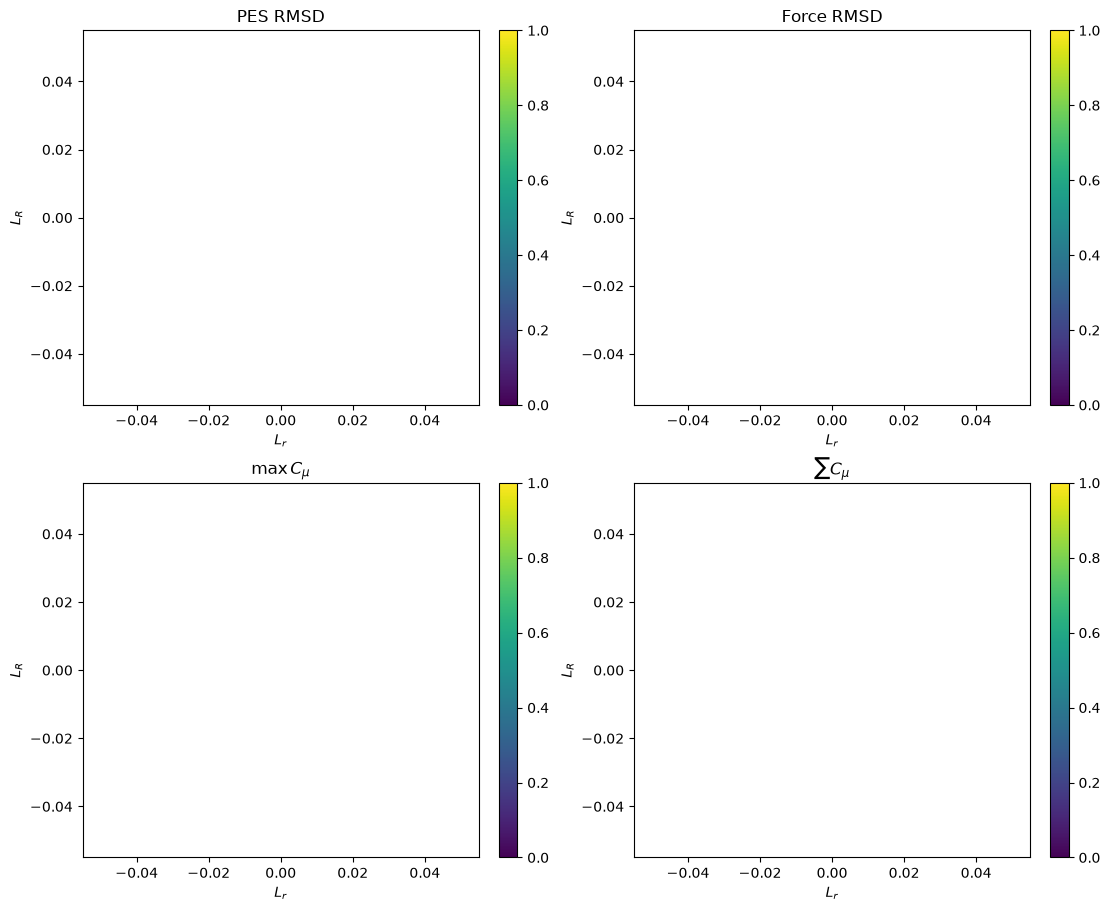

In [200]:
from matplotlib.colors import LogNorm


fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 9),
    constrained_layout=True
)

axes = axes.ravel()


for ax, (metric, title) in zip(
    axes,
    metrics
):

    z = df_plot[metric].to_numpy()

    positive = z[z > 0]

    norm = None

    if len(positive) > 0:
        norm = LogNorm(
            vmin=positive.min(),
            vmax=positive.max()
        )

    sc = ax.scatter(
        df_plot["box_r"],
        df_plot["box_R"],
        c=z,
        s=180,
        cmap="viridis",
        norm=norm,
        edgecolors="black"
    )

    ax.set_xlabel(
        r"$L_r$"
    )

    ax.set_ylabel(
        r"$L_R$"
    )

    ax.set_title(
        title
    )

    fig.colorbar(
        sc,
        ax=ax
    )


plt.show()

### Optional coefficient diagnostics for reduced fits


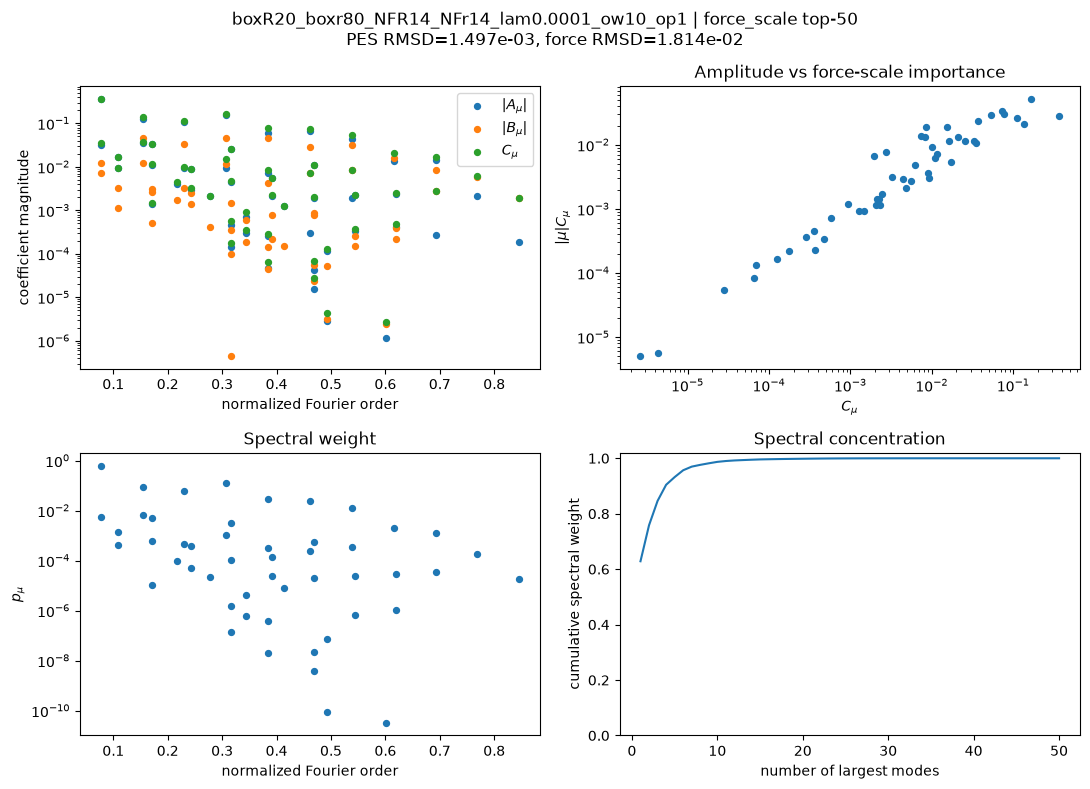

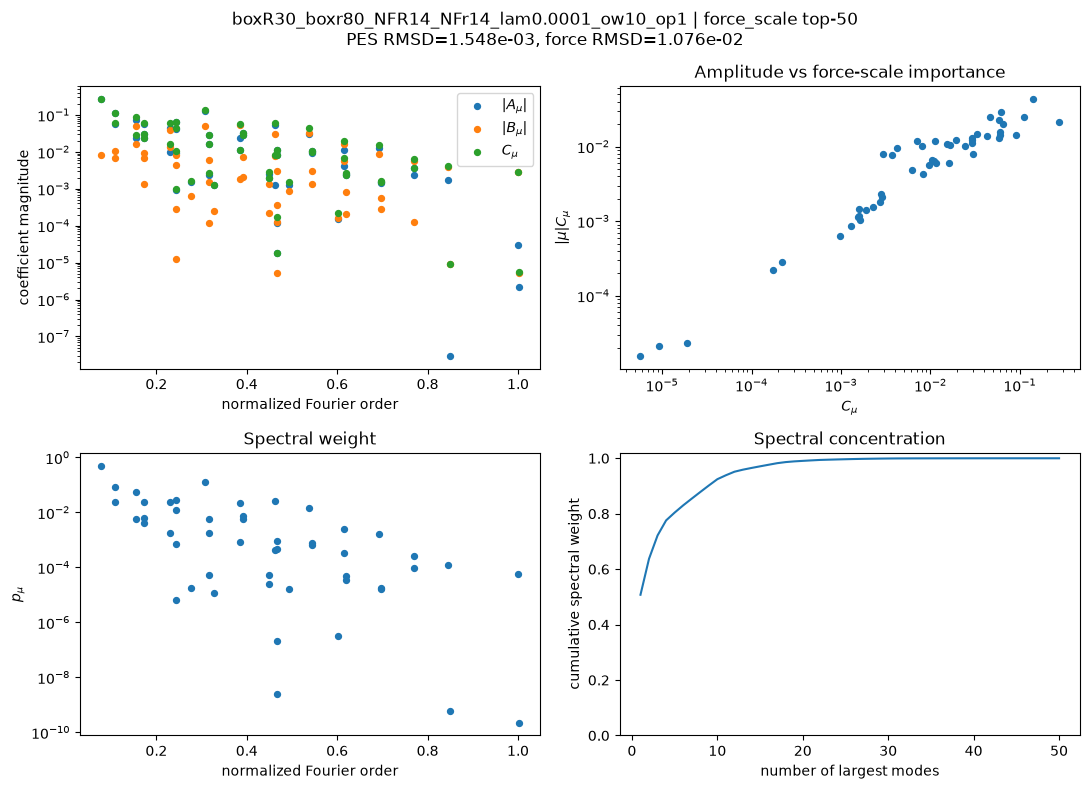

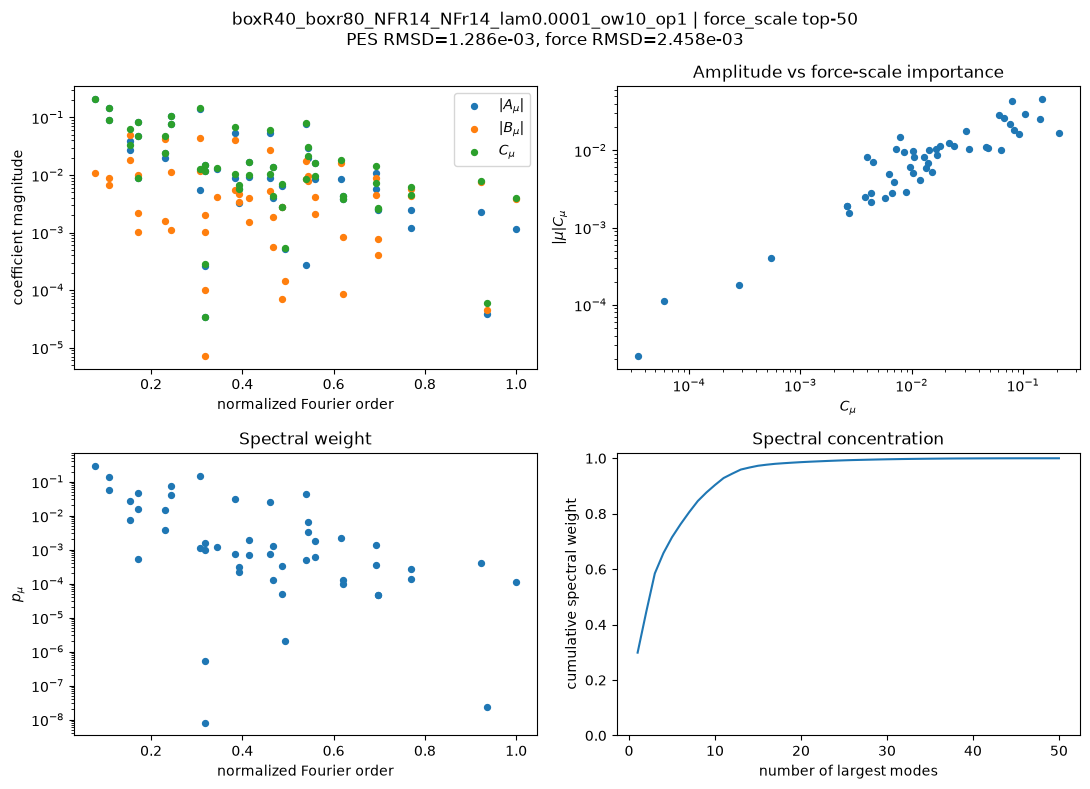

In [201]:

def reduced_run_label(fit):
    return (
        f"{fit['parent_id']} | "
        f"{fit['selection_method']} top-{fit['top_n_requested']}"
    )


def plot_fit_coefficient_statistics(fit):
    A = fit['A']
    B = fit['B']
    amplitude = fit['amplitude']
    force_scale = fit['force_scale']
    p_mode = fit['mode_probability']
    order_norm = fit['order_norm']

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))

    ax = axes[0, 0]
    ax.scatter(order_norm, np.abs(A), s=18, label=r'$|A_\mu|$')
    ax.scatter(order_norm, np.abs(B), s=18, label=r'$|B_\mu|$')
    ax.scatter(order_norm, amplitude, s=18, label=r'$C_\mu$')
    ax.set_yscale('log')
    ax.set_xlabel('normalized Fourier order')
    ax.set_ylabel('coefficient magnitude')
    ax.legend()

    ax = axes[0, 1]
    ax.scatter(amplitude, force_scale, s=18)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$C_\mu$')
    ax.set_ylabel(r'$|\mu|C_\mu$')
    ax.set_title('Amplitude vs force-scale importance')

    ax = axes[1, 0]
    positive = p_mode > 0
    ax.scatter(order_norm[positive], p_mode[positive], s=18)
    if np.any(positive):
        ax.set_yscale('log')
    ax.set_xlabel('normalized Fourier order')
    ax.set_ylabel(r'$p_\mu$')
    ax.set_title('Spectral weight')

    ax = axes[1, 1]
    p_sorted = np.sort(p_mode)[::-1]
    ax.plot(
        np.arange(1, len(p_sorted) + 1),
        np.cumsum(p_sorted),
    )
    ax.set_ylim(0.0, 1.02)
    ax.set_xlabel('number of largest modes')
    ax.set_ylabel('cumulative spectral weight')
    ax.set_title('Spectral concentration')

    fig.suptitle(
        reduced_run_label(fit)
        + f"\nPES RMSD={fit['metrics']['v_rmse']:.3e}, "
        + f"force RMSD={fit['metrics']['force_combined_rmse']:.3e}"
    )

    plt.tight_layout()
    plt.show()


if PLOT_REDUCED_COEFFICIENTS:
    for fit in reduced_fits:
        plot_fit_coefficient_statistics(fit)



## Stage 6 — Classical CPU dynamics for the reduced candidates

The exact full-\(V_{\rm SM}\) CPU reference is generated once. Each reduced fit is then projected into the unchanged Fock basis and propagated with \(H=T_r+T_R+V_{\rm fit}\).


In [202]:

EXACT_CPU_FILE = RESULTS_DIR / 'psi_t_exact_fullV.npz'


def dynamics_filename(fit):
    safe_id = fit['fit_id'].replace('/', '_')
    return RESULTS_DIR / f'dynamics_{safe_id}.npz'


if SKIP_EXISTING_DYNAMICS and EXACT_CPU_FILE.exists():
    with np.load(EXACT_CPU_FILE, allow_pickle=False) as data:
        psi_t_exact = data['psi_t']
    print('loaded exact CPU:', EXACT_CPU_FILE)

else:
    print('building exact full-V potential matrix...')
    V_exact_mat = potential_matrix(V_SM)

    print('propagating exact CPU reference...')
    psi_t_exact = evolve_cpu_fullV(
        V_exact_mat,
        psi0_cpu,
        times,
    )

    np.savez_compressed(
        EXACT_CPU_FILE,
        psi_t=psi_t_exact,
        times=times,
    )

    print('saved:', EXACT_CPU_FILE)


dynamics_runs = []

for i, fit in enumerate(reduced_fits, start=1):
    path = dynamics_filename(fit)

    print()
    print(f'[{i}/{len(reduced_fits)}]', fit['fit_id'])

    if SKIP_EXISTING_DYNAMICS and path.exists():
        with np.load(path, allow_pickle=False) as data:
            psi_t_fit = data['psi_t']

        print('loaded:', path.name)

    else:
        def V_fit_current(r, R, fit=fit):
            return evaluate_fourier_full_V(r, R, fit)

        print('building fitted potential matrix...')
        V_fit_mat = potential_matrix(V_fit_current)

        print('propagating CPU dynamics...')
        psi_t_fit = evolve_cpu_fullV(
            V_fit_mat,
            psi0_cpu,
            times,
        )

        np.savez_compressed(
            path,
            psi_t=psi_t_fit,
            times=times,
            fit_id=np.array(fit['fit_id']),
            parent_id=np.array(fit['parent_id']),
            selection_method=np.array(fit['selection_method']),
            top_n_requested=np.array(fit['top_n_requested']),
            fourier_box=fit['fourier_box'],
            NF=fit['NF'],
            mvec=fit['mvec'],
            mu_phys=fit['mu_phys'],
            C0=np.array(fit['C0']),
            A=fit['A'],
            B=fit['B'],
        )

        print('saved:', path.name)

    dynamics_runs.append({
        'fit': fit,
        'psi_t': psi_t_fit,
        'path': path,
    })


loaded exact CPU: fullV_sparse_fourier_workflow/psi_t_exact_fullV.npz

[1/3] boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50
building fitted potential matrix...
propagating CPU dynamics...
saved: dynamics_boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50.npz

[2/3] boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50
building fitted potential matrix...
propagating CPU dynamics...
saved: dynamics_boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50.npz

[3/3] boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50
building fitted potential matrix...
propagating CPU dynamics...
saved: dynamics_boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_sel-force_scale_top50.npz



## Dynamics metrics and trajectory plots

The final table adds time-domain errors in \(\langle r\rangle\), \(\langle R\rangle\), \(\sigma_r\), and \(\sigma_R\) relative to the exact full-potential CPU reference.


In [203]:

mr_exact, sr_exact, mR_exact, sR_exact = cpu_moments(
    psi_t_exact
)

dynamics_rows = []

for run in dynamics_runs:
    fit = run['fit']

    mr, sr, mR, sR = cpu_moments(
        run['psi_t']
    )

    row = fit_summary_row(fit)

    row.update({
        'dyn_rmse_mean_r': float(np.sqrt(np.mean((mr - mr_exact)**2))),
        'dyn_rmse_mean_R': float(np.sqrt(np.mean((mR - mR_exact)**2))),
        'dyn_rmse_sigma_r': float(np.sqrt(np.mean((sr - sr_exact)**2))),
        'dyn_rmse_sigma_R': float(np.sqrt(np.mean((sR - sR_exact)**2))),
    })

    row['dyn_combined_rmse'] = float(np.sqrt(
        0.25 * (
            row['dyn_rmse_mean_r']**2
            + row['dyn_rmse_mean_R']**2
            + row['dyn_rmse_sigma_r']**2
            + row['dyn_rmse_sigma_R']**2
        )
    ))

    dynamics_rows.append(row)

dynamics_summary_df = pd.DataFrame(
    dynamics_rows
).sort_values(
    'dyn_combined_rmse'
).reset_index(drop=True)

dynamics_summary_csv = RESULTS_DIR / 'dynamics_summary.csv'
dynamics_summary_df.to_csv(
    dynamics_summary_csv,
    index=False,
)

print('saved:', dynamics_summary_csv)
dynamics_summary_df


saved: fullV_sparse_fourier_workflow/dynamics_summary.csv


,fit_id,parent_id,basis,box_R,box_r,NF_R,NF_r,ridge_lambda,order_strength,order_power,...,effective_modes,theta_max,theta_sum,max_kappa,n_tgifs_gates,dyn_rmse_mean_r,dyn_rmse_mean_R,dyn_rmse_sigma_r,dyn_rmse_sigma_R,dyn_combined_rmse
0,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR40_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,40.0,80.0,14,14,0.0001,10.0,1.0,...,6.781804,0.586864,5.243528,2.483647,100,0.067634,0.032099,0.073040,0.007486,0.052430
1,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR30_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,30.0,80.0,14,14,0.0001,10.0,1.0,...,3.461536,0.765835,4.760830,2.483647,100,0.323952,0.197465,0.128428,0.090228,0.205288
2,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1_s...,boxR20_boxr80_NFR14_NFr14_lam0.0001_ow10_op1,half_lattice,20.0,80.0,14,14,0.0001,10.0,1.0,...,2.354789,1.021633,4.367565,2.483647,100,0.437992,0.270038,0.162033,0.126646,0.277061


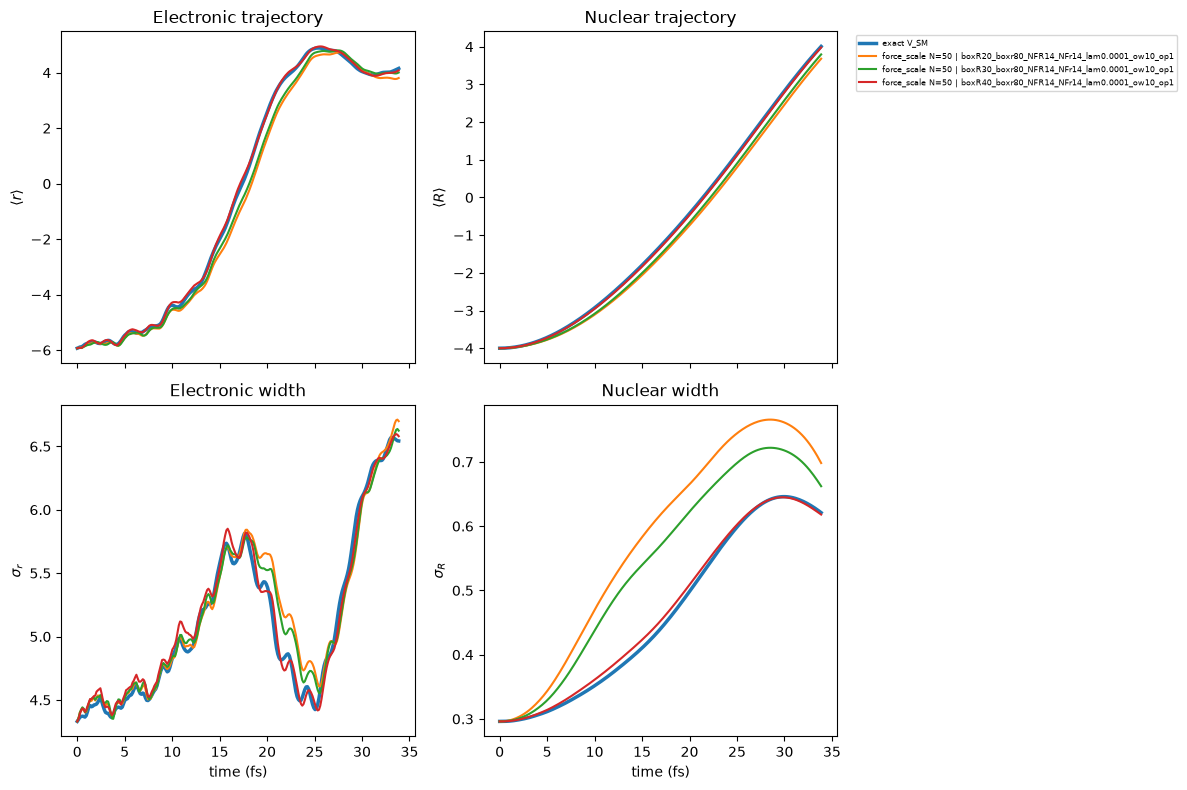

In [204]:

t_fs = times * AU_TIME_TO_FS

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    sharex=True,
)

axes[0, 0].plot(t_fs, mr_exact, linewidth=2.5, label='exact V_SM')
axes[0, 1].plot(t_fs, mR_exact, linewidth=2.5, label='exact V_SM')
axes[1, 0].plot(t_fs, sr_exact, linewidth=2.5, label='exact V_SM')
axes[1, 1].plot(t_fs, sR_exact, linewidth=2.5, label='exact V_SM')

for run in dynamics_runs[0:6]:
    fit = run['fit']
    mr, sr, mR, sR = cpu_moments(run['psi_t'])

    label = (
        f"{fit['selection_method']} "
        f"N={fit['metrics']['n_modes']} | "
        f"{fit['parent_id']}"
    )

    axes[0, 0].plot(t_fs, mr, label=label)
    axes[0, 1].plot(t_fs, mR, label=label)
    axes[1, 0].plot(t_fs, sr, label=label)
    axes[1, 1].plot(t_fs, sR, label=label)

axes[0, 0].set_ylabel(r'$\langle r\rangle$')
axes[0, 1].set_ylabel(r'$\langle R\rangle$')
axes[1, 0].set_ylabel(r'$\sigma_r$')
axes[1, 1].set_ylabel(r'$\sigma_R$')

axes[1, 0].set_xlabel('time (fs)')
axes[1, 1].set_xlabel('time (fs)')

axes[0, 0].set_title('Electronic trajectory')
axes[0, 1].set_title('Nuclear trajectory')
axes[1, 0].set_title('Electronic width')
axes[1, 1].set_title('Nuclear width')

axes[0, 1].legend(
    fontsize=6,
    bbox_to_anchor=(1.04, 1),
    loc='upper left',
)

plt.tight_layout()
plt.show()



## Practical use

A sensible workflow is:

1. Set one large fixed `FOURIER_ORDERS` value and verify separately that making it larger does not materially improve the best raw fits.
2. Sweep the Fourier box and regularization.
3. Use `RAW_V_RMSE_MAX` only as a coarse rejection filter.
4. Compare both top-\(N\) ranking rules.
5. Inspect PES, force, coefficient, and TGIFS metrics on the **refitted reduced supports**.
6. Let the CPU dynamics determine which sparse representations are actually adequate.

The best representation need not have the smallest PES RMSD. For TGIFS, a slightly less accurate PES can be preferable if it gives much smaller coefficients and many fewer gates without changing the relevant dynamics.


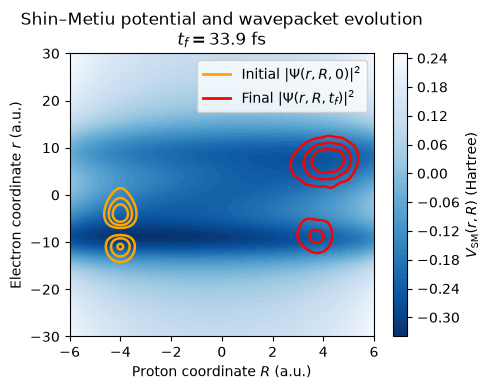

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Load exact CPU dynamics
# ------------------------------------------------------------

exact_file = RESULTS_DIR / "psi_t_exact_fullV.npz"

# For the TGIFS notebook's saved CPU reference, use instead:
# exact_file = RESULTS_DIR / "psi_t_cpu_exact_fullV.npz"

with np.load(exact_file) as data:
    psi_initial = data["psi_t"][0].reshape(Nr, NR)
    psi_final   = data["psi_t"][-1].reshape(Nr, NR)

    t_final = (
        data["times"][-1]
        if "times" in data.files
        else times[-1]
    )


# ------------------------------------------------------------
# 2. Physical-coordinate grid
# ------------------------------------------------------------

r_grid = np.linspace(-30.0, 30.0, 301)
R_grid = np.linspace(-6.0, 6.0, 241)

# Shape: (len(r_grid), len(R_grid))
R_mesh, r_mesh = np.meshgrid(
    R_grid,
    r_grid,
    indexing="xy"
)

# Exact Shin-Metiu potential
V_grid = V_SM(r_mesh, R_mesh)


# ------------------------------------------------------------
# 3. Harmonic-oscillator basis functions in position space
# ------------------------------------------------------------

def ho_basis_position(x, N, length, center=0.0):
    """
    Normalized HO wavefunctions phi_n(x).

    Returns shape (N, len(x)).
    Uses a stable recurrence instead of explicit Hermite polynomials.
    """

    xi = (np.asarray(x) - center) / length

    basis = np.zeros(
        (N, len(xi)),
        dtype=float
    )

    basis[0] = (
        np.pi**(-0.25)
        / np.sqrt(length)
        * np.exp(-0.5 * xi**2)
    )

    if N > 1:
        basis[1] = np.sqrt(2.0) * xi * basis[0]

    for n in range(1, N - 1):
        basis[n + 1] = (
            np.sqrt(2.0 / (n + 1)) * xi * basis[n]
            - np.sqrt(n / (n + 1)) * basis[n - 1]
        )

    return basis


Br = ho_basis_position(
    r_grid, Nr, l_r, r0
)

BR = ho_basis_position(
    R_grid, NR, l_R, R0
)


# ------------------------------------------------------------
# 4. Reconstruct 2D wavefunctions
# ------------------------------------------------------------

# Psi(r,R) = sum_n,m c_nm phi_n(r) phi_m(R)

Psi_initial = Br.T @ psi_initial @ BR
Psi_final   = Br.T @ psi_final   @ BR

rho_initial = np.abs(Psi_initial)**2
rho_final   = np.abs(Psi_final)**2


# Normalize each density to its own maximum
# (for displaying relative-density contours)
rho_initial_plot = rho_initial / rho_initial.max()
rho_final_plot   = rho_final   / rho_final.max()


# ------------------------------------------------------------
# 5. Plot PES with initial and final wavepacket contours
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 4))

# Exact potential
pes = ax.contourf(
    R_mesh,
    r_mesh,
    V_grid,
    levels=60,
    cmap="Blues_r"#"RdBu_r"
)

fig.colorbar(
    pes,
    ax=ax,
    label=r"$V_{\mathrm{SM}}(r,R)$ (Hartree)"
)

# Contour levels as fractions of each density maximum
density_levels = [0.1, 0.3, 0.6]

# Initial wavepacket
ax.contour(
    R_mesh,
    r_mesh,
    rho_initial_plot,
    levels=density_levels,
    colors="orange",
    linewidths=1.8,
)

# Final wavepacket
ax.contour(
    R_mesh,
    r_mesh,
    rho_final_plot,
    levels=density_levels,
    colors="red",
    linewidths=1.8,
)

# Legend
legend_elements = [
    Line2D(
        [0], [0],
        color="orange",
        lw=2,
        label=r"Initial $|\Psi(r,R,0)|^2$"
    ),
    Line2D(
        [0], [0],
        color="red",
        lw=2,
        label=rf"Final $|\Psi(r,R,t_f)|^2$"
    ),
]

ax.legend(handles=legend_elements, loc="upper right")

ax.set_xlabel(r"Proton coordinate $R$ (a.u.)")
ax.set_ylabel(r"Electron coordinate $r$ (a.u.)")

ax.set_title(
    rf"Shin–Metiu potential and wavepacket evolution"
    "\n"
    rf"$t_f={t_final * AU_TIME_TO_FS:.1f}$ fs"
)

plt.tight_layout()
plt.savefig("shin_metiu_2D_potential.pdf")
plt.show()